# AnyCam — 05b · Step 7 round 2: SVCT improved

Round 1: regression fixed on all cameras, cultivar not yet (best 0.64 vs 0.76 target). Round 2 changes:
- **teacher mode**: every batch = full 204-band view (teacher) + one virtual camera (student learns from teacher, weight 0.5)
- **mixed camera sampler**: 1/3 phone-like, 1/3 drone-like, 1/3 random (the 7 real cameras stay held out)
- **longer training**: up to 80 epochs, patience 30, checkpoint chosen by validation accuracy + R2

Runs (~3-4 h total): SVCT round 2 · no-consistency round 2 · no-wavelength-layer round 2 · 4 extra camera-specific models.
Setup: **HyperLeaf2024 (trophy)**, **GPU T4 x2**, **Internet On**. Before saving to GitHub check the repository is
**ShahnawazQ007/one-model-many-camera**, file `kaggle_runs/05b_step7_round2.ipynb`.

In [1]:
import os, subprocess, glob, json, pathlib
REPO = 'https://github.com/ShahnawazQ007/one-model-many-camera.git'
if not os.path.exists('/kaggle/working/anycam'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', REPO, '/kaggle/working/anycam'], check=True)
else:
    subprocess.run(['git', '-C', '/kaggle/working/anycam', 'pull', '-q'], check=True)
os.chdir('/kaggle/working/anycam')
!pip -q install timm tifffile imagecodecs
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - turn on the GPU accelerator!')
hits = [os.path.dirname(f) for f in glob.glob('/kaggle/input/**/train.csv', recursive=True)
        if os.path.isdir(os.path.join(os.path.dirname(f), 'images'))]
assert hits, 'Add Input -> search hyperleaf -> the one with the trophy icon'
DATA = hits[0]; print('data:', DATA, '| images:', len(glob.glob(f'{DATA}/images/*.tiff')))

GPU: Tesla T4
data: /kaggle/input/competitions/HyperLeaf2024 | images: 2410


In [2]:
# 1) SVCT round 2 (ours)
!python experiments/train_svct.py --data {DATA} --stem hyper --views 2 --cons-mode teacher --cons 0.5 --radio 0.5 --sampler mixed --select acc --epochs 80 --patience 30 --out runs/svct_r2

device cuda | train 1410 val 180 test 820 leaves | stem hyper views 2 cons 0.5 radio 0.5 held-out all

model.safetensors: downloading bytes: ▊                     | 1.72MB            
model.safetensors: downloading bytes: ████▉                 | 10.5MB,   ???B/s  
model.safetensors: downloading bytes: ███████▍              | 15.9MB, 1.32MB/s  
model.safetensors: downloading bytes: ██████████████▎       | 30.5MB, 2.21MB/s  
model.safetensors: downloading bytes: ██████████████████████| 44.0MB, 4.21MB/s  
model.safetensors: reconstructing file: 100%|██████| 46.8MB / 46.8MB, 4.50MB/s  
model resnet18 (hyper stem): 11.60M parameters
epoch  0 train 2.271 val 2.638 acc 0.173 mse 1.220 (45s)
epoch  1 train 2.003 val 2.485 acc 0.327 mse 1.070 (79s)
epoch  2 train 1.758 val 2.617 acc 0.325 mse 1.045 (114s)
epoch  3 train 1.614 val 2.565 acc 0.356 mse 1.096 (150s)
epoch  4 train 1.481 val 2.473 acc 0.394 mse 1.031 (186s)
epoch  5 train 1.397 val 2.510 acc 0.462 mse 1.088 (222s)
epoch  6 train 1.3

In [3]:
# 2) ablation: no consistency (one camera per batch, full bands 30% of the time)
!python experiments/train_svct.py --data {DATA} --stem hyper --views 1 --p-full 0.3 --radio 0.5 --sampler mixed --select acc --epochs 80 --patience 30 --out runs/svct_r2_nocons

device cuda | train 1410 val 180 test 820 leaves | stem hyper views 1 cons 0.0 radio 0.5 held-out all
model resnet18 (hyper stem): 11.60M parameters
epoch  0 train 2.296 val 2.784 acc 0.056 mse 1.343 (32s)
epoch  1 train 2.071 val 2.571 acc 0.264 mse 1.146 (56s)
epoch  2 train 1.826 val 2.497 acc 0.280 mse 0.909 (79s)
epoch  3 train 1.609 val 2.613 acc 0.256 mse 1.003 (103s)
epoch  4 train 1.478 val 2.522 acc 0.370 mse 1.076 (128s)
epoch  5 train 1.385 val 2.429 acc 0.377 mse 1.038 (153s)
epoch  6 train 1.309 val 2.376 acc 0.382 mse 0.926 (176s)
epoch  7 train 1.225 val 1.919 acc 0.539 mse 0.801 (200s)
epoch  8 train 1.182 val 2.383 acc 0.449 mse 1.035 (225s)
epoch  9 train 1.109 val 2.430 acc 0.445 mse 1.032 (250s)
epoch 10 train 1.013 val 2.417 acc 0.408 mse 0.918 (274s)
epoch 11 train 0.994 val 2.448 acc 0.528 mse 1.168 (298s)
epoch 12 train 0.983 val 2.516 acc 0.405 mse 0.885 (320s)
epoch 13 train 0.929 val 2.411 acc 0.501 mse 1.060 (344s)
epoch 14 train 0.896 val 2.408 acc 0.415 m

In [4]:
# 3) ablation: no wavelength layer (bands interpolated to 204), same teacher + sampler
!python experiments/train_svct.py --data {DATA} --stem interp --views 2 --cons-mode teacher --cons 0.5 --radio 0.5 --sampler mixed --select acc --epochs 80 --patience 30 --out runs/svct_r2_interp

device cuda | train 1410 val 180 test 820 leaves | stem interp views 2 cons 0.5 radio 0.5 held-out all
model resnet18 (interp stem): 11.81M parameters
epoch  0 train 2.311 val 2.406 acc 0.085 mse 0.923 (68s)
epoch  1 train 2.049 val 2.409 acc 0.269 mse 1.000 (128s)
epoch  2 train 1.886 val 2.848 acc 0.258 mse 1.208 (189s)
epoch  3 train 1.790 val 2.593 acc 0.231 mse 0.905 (250s)
epoch  4 train 1.629 val 2.613 acc 0.303 mse 0.982 (311s)
epoch  5 train 1.555 val 2.467 acc 0.292 mse 0.820 (371s)
epoch  6 train 1.467 val 2.560 acc 0.333 mse 1.101 (431s)
epoch  7 train 1.426 val 2.529 acc 0.302 mse 0.854 (491s)
epoch  8 train 1.341 val 2.386 acc 0.344 mse 0.766 (552s)
epoch  9 train 1.326 val 2.558 acc 0.372 mse 0.913 (613s)
epoch 10 train 1.303 val 2.716 acc 0.353 mse 0.951 (673s)
epoch 11 train 1.221 val 2.292 acc 0.397 mse 0.720 (733s)
epoch 12 train 1.165 val 2.472 acc 0.395 mse 0.692 (793s)
epoch 13 train 1.184 val 2.484 acc 0.457 mse 0.856 (854s)
epoch 14 train 1.145 val 2.773 acc 0.3

In [5]:
# first comparison (before the extra camera-specific models)
!python scripts/plot_step7.py --baseline results/step06_camera_test/camera_eval.csv --runs "SVCT r2 (ours)=runs/svct_r2" "no consistency r2=runs/svct_r2_nocons" "no wavelength layer r2=runs/svct_r2_interp" --out runs/step7_r2_compare
!for f in runs/svct_*/camera_eval.csv; do echo "### $f"; cat $f; done

Mean over the 7 real camera profiles (cameras the SVCT models never saw):
                 method   condition  cultivar_acc  Fertilizer_R2  GrainWeight_R2  PhiPS2_R2
204-band model (Step 6)       drift         0.521         -0.369          -0.667     -0.579
204-band model (Step 6) drift+radio         0.505         -0.488          -0.752     -0.695
204-band model (Step 6)     nominal         0.522         -0.364          -0.685     -0.562
204-band model (Step 6) radiometric         0.504         -0.509          -0.790     -0.567
         SVCT r2 (ours)       drift         0.566          0.485           0.479      0.224
         SVCT r2 (ours) drift+radio         0.551          0.357           0.384      0.166
         SVCT r2 (ours)     nominal         0.551          0.526           0.508      0.226
         SVCT r2 (ours) radiometric         0.549          0.456           0.446      0.196
      no consistency r2       drift         0.664          0.507           0.443      0.307
      

In [6]:
# 4) camera-specific models for the 4 cameras not yet done (completes the 'one model per camera' reference)
for cam in ['dji_p4_multispectral', 'parrot_sequoia', 'generic_rgb_nir', 'micasense_no_red_edge']:
    !python experiments/train_baseline.py --data {DATA} --split official --camera {cam} --upscale 2 --aug strong --epochs 50 --patience 12 --out runs/oracle_{cam}

device cuda | train 1410 val 180 test 820 leaves
model resnet18: 11.19M parameters
epoch  0 train 2.178 val 1.894 (45s)
epoch  1 train 1.761 val 1.868 (83s)
epoch  2 train 1.473 val 1.504 (120s)
epoch  3 train 1.218 val 1.491 (157s)
epoch  4 train 1.060 val 1.316 (193s)
epoch  5 train 0.935 val 1.422 (230s)
epoch  6 train 0.819 val 1.425 (266s)
epoch  7 train 0.744 val 1.268 (301s)
epoch  8 train 0.666 val 1.286 (337s)
epoch  9 train 0.673 val 1.212 (374s)
epoch 10 train 0.596 val 1.197 (409s)
epoch 11 train 0.602 val 1.296 (445s)
epoch 12 train 0.530 val 1.154 (481s)
epoch 13 train 0.521 val 1.648 (516s)
epoch 14 train 0.486 val 1.055 (553s)
epoch 15 train 0.476 val 1.501 (589s)
epoch 16 train 0.437 val 1.210 (626s)
epoch 17 train 0.414 val 0.985 (661s)
epoch 18 train 0.412 val 1.137 (697s)
epoch 19 train 0.392 val 1.108 (733s)
epoch 20 train 0.380 val 1.308 (769s)
epoch 21 train 0.344 val 0.898 (805s)
epoch 22 train 0.354 val 1.330 (841s)
epoch 23 train 0.346 val 1.030 (876s)
epoch 2

Mean over the 7 real camera profiles (cameras the SVCT models never saw):
                 method   condition  cultivar_acc  Fertilizer_R2  GrainWeight_R2  PhiPS2_R2
204-band model (Step 6)       drift         0.521         -0.369          -0.667     -0.579
204-band model (Step 6) drift+radio         0.505         -0.488          -0.752     -0.695
204-band model (Step 6)     nominal         0.522         -0.364          -0.685     -0.562
204-band model (Step 6) radiometric         0.504         -0.509          -0.790     -0.567
         SVCT r2 (ours)       drift         0.566          0.485           0.479      0.224
         SVCT r2 (ours) drift+radio         0.551          0.357           0.384      0.166
         SVCT r2 (ours)     nominal         0.551          0.526           0.508      0.226
         SVCT r2 (ours) radiometric         0.549          0.456           0.446      0.196
      no consistency r2       drift         0.664          0.507           0.443      0.307
      

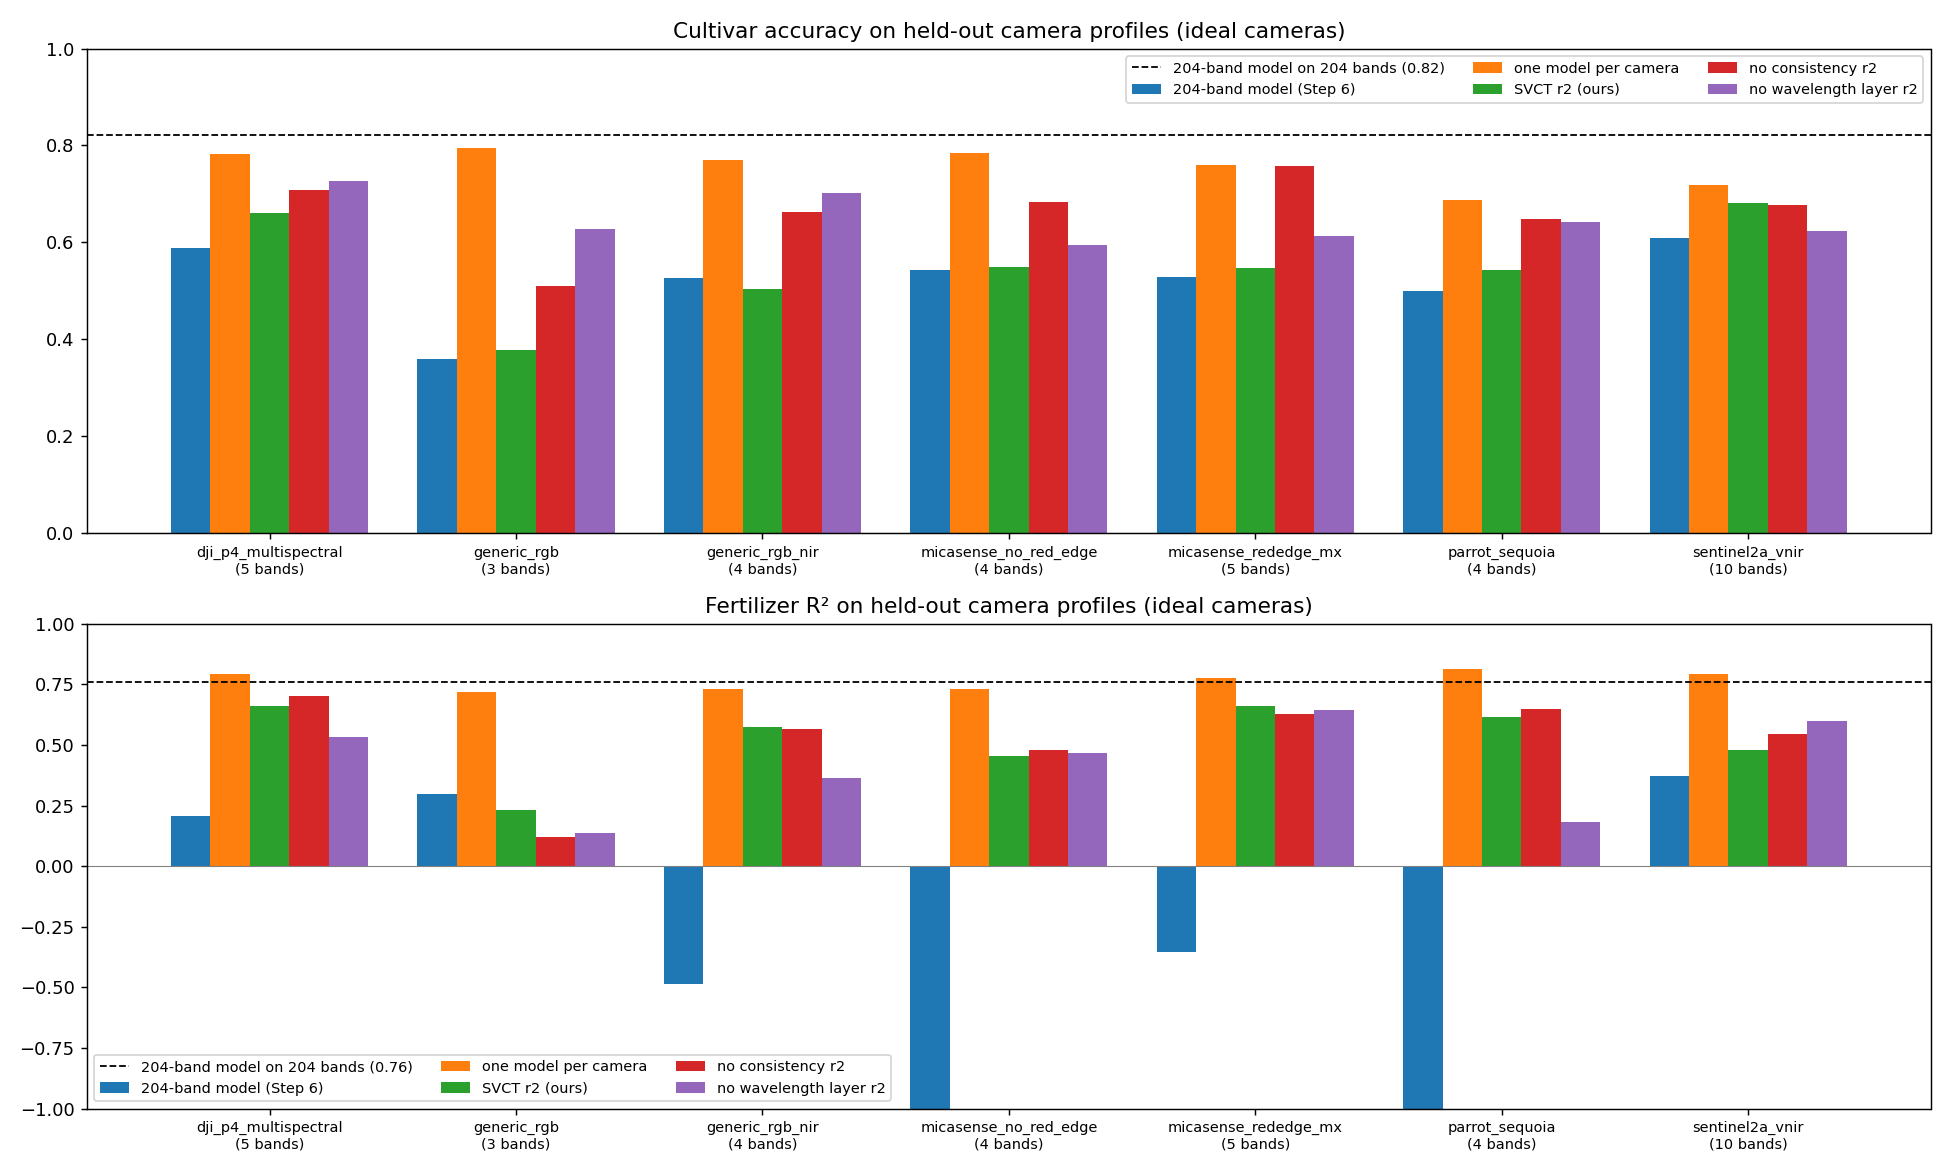

### runs/oracle_dji_p4_multispectral/metrics.json
{
 "split": "official",
 "seed": 0,
 "fold": 0,
 "backbone": "resnet18",
 "best_epoch": 21,
 "upscale": 2.0,
 "aug": "strong",
 "camera": "dji_p4_multispectral",
 "n_test": 820,
 "cultivar": {
  "accuracy": 0.7817073170731708,
  "macro_f1": 0.7741001073327313
 },
 "GrainWeight": {
  "R2": 0.7114541846291325,
  "RMSE": 1072.0557609562475
 },
 "Gsw": {
  "R2": 0.14327247189008097,
  "RMSE": 0.025184649023209577
 },
 "PhiPS2": {
  "R2": 0.47835009561907604,
  "RMSE": 0.07861934817444884
 },
 "Fertilizer": {
  "R2": 0.7909589271397718,
  "RMSE": 0.20759779847031795
 }
}### runs/oracle_generic_rgb_nir/metrics.json
{
 "split": "official",
 "seed": 0,
 "fold": 0,
 "backbone": "resnet18",
 "best_epoch": 17,
 "upscale": 2.0,
 "aug": "strong",
 "camera": "generic_rgb_nir",
 "n_test": 820,
 "cultivar": {
  "accuracy": 0.7707317073170732,
  "macro_f1": 0.7581548410479211
 },
 "GrainWeight": {
  "R2": 0.6674605548000787,
  "RMSE": 1150.884043283133


In [7]:
# final comparison with all 7 camera-specific models
!python scripts/plot_step7.py --baseline results/step06_camera_test/camera_eval.csv --oracles "runs/oracle_*" --runs "SVCT r2 (ours)=runs/svct_r2" "no consistency r2=runs/svct_r2_nocons" "no wavelength layer r2=runs/svct_r2_interp" --out runs/step7_r2_compare
from IPython.display import Image, display
display(Image('runs/step7_r2_compare/step7_compare.png'))
!for f in runs/oracle_*/metrics.json; do echo "### $f"; cat $f; done

## Done
**Save Version → Quick Save** → GitHub: repository **ShahnawazQ007/one-model-many-camera**, branch main,
file `kaggle_runs/05b_step7_round2.ipynb`. Then stop the session (power button) and tell Claude "done".